# 03 — Visualising the graph
Lecture 1, ~19-24% (search: "nicely visualize these expressions"). Phase 1, item 3 in [PLAN](../knowledge/PLAN.md). Previous: [02-value-object](../knowledge/notes/02-value-object.md).

**Where this fits.** Item 2 gave every `Value` a receipt. Printing it works for 3 nodes and stops working for 30. Today you draw it. Item 4 fills in a slope on every box of this same picture, by hand, starting from the end.

**Done when** `draw_dot(L)` shows `a`, `b`, `c`, `e`, `d`, `f`, `L` with the right numbers, and you can point at the picture and say which way data flows and which way slopes will flow.

Pure Python. `graphviz` is only used for drawing.

## 0. Check the drawing tool
The pip `graphviz` package only calls a separate program named `dot`. If this prints `None`, run `! sudo apt install -y graphviz` in Claude Code, then restart the kernel. Sections 1-2 work without it.

In [5]:
import shutil
print(shutil.which('dot'))  # a path means you can draw

/usr/bin/dot


## 1. Your Value, plus a label
Copy your `Value` class from notebook 02 into the cell below. Then add one field: `label`, an empty string by default, so you can pass a name like `Value(2.0, label='a')`.

Question: should `__add__` and `__mul__` give their result a label? Who knows the name `e` at that moment?

In [6]:
class Value:
    def __init__(self, data, label=""):
        self.data = data
        # this field will be used to track the previous Value in the computational graph
        self._prev = ()
        # this field will be used to track the operation that produced this Value
        self._op = ""
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # create a new Value object to represent the result of the addition
        out = Value(self.data + other.data, label=f"{self.label}+{other.label}")
        # set the _prev field to track the previous Values in the computational graph
        out._prev = (self, other)
        # set the _op field to indicate that this Value was produced by addition
        out._op = "+"
        return out

    def __mul__(self, other):
        # create a new Value object to represent the result of the multiplication
        out = Value(self.data * other.data, label=f"{self.label}*{other.label}")
        # set the _prev field to track the previous Values in the computational graph
        out._prev = (self, other)
        # set the _op field to indicate that this Value was produced by multiplication
        out._op = "*"
        return out

## 2. One layer deeper
Build this, giving every value its label. For `e` and `d`, set `.label` after the operation creates them.

```
a = 2.0    b = -3.0    c = 10.0    f = -2.0
e = a * b
d = e + c
L = d * f
```

**Predict `L.data` before you run it.** Then check it with your `traverse_graph` from notebook 02.

In [10]:
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
f = Value(-2.0, label="f")

e = a * b # Value(data=-6.0, label="a*b")
d = e + c # Value(data=4.0, label="a*b+c")
L = d * f  # Value(data=-8.0, label="a*b+c*f")


def traverse_graph(value):
    if value._prev is not None:
        print(value._op)
    for node in value._prev:
        print(node, node.label)
        traverse_graph(node)

traverse_graph(L)

*
Value(data=4.0) a*b+c
+
Value(data=-6.0) a*b
*
Value(data=2.0) a

Value(data=-3.0) b

Value(data=10.0) c

Value(data=-2.0) f



## 3. The drawing helper (scaffolding)
Run this cell, don't study it. Two things worth knowing:
- `trace` is your `traverse_graph`, except it collects nodes into a set and doesn't print them.
- The small `+` / `*` circles are **not** `Value`s. The drawing adds them so you can see which op made which box. Only the boxes are real `Value`s.

In [11]:
# SCAFFOLDING (written by Claude): draws the receipt. You don't need to type this.
# Adapted from Karpathy's draw_dot in lectures/micrograd/micrograd_lecture_first_half_roughly.ipynb
from graphviz import Digraph

def trace(root):
    # walk _prev from the root (same idea as your traverse_graph), collect every node and edge once
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        label = getattr(n, 'label', '')      # works before you've added .label
        text = f"{{ {label} | data {n.data:.4f} }}"
        if hasattr(n, 'grad'):               # shows up once you add .grad in item 4
            text = f"{{ {label} | data {n.data:.4f} | grad {n.grad:.4f} }}"
        dot.node(name=uid, label=text, shape='record')   # a box per Value
        if n._op:
            dot.node(name=uid + n._op, label=n._op)       # a small op node (not a real Value)
            dot.edge(uid + n._op, uid)
    for child, parent in edges:
        dot.edge(str(id(child)), str(id(parent)) + parent._op)
    return dot


## 4. Draw it
Call `draw_dot(L)`. Check it against section 2: every box, every op, every arrow. Read it left to right: that's the forward pass.

Question: item 4 starts at `L` and works out "how much does L care about this box?" for each box. Which box do you fill in first, and which last?

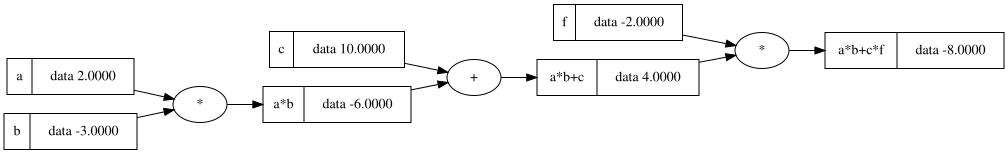

In [12]:
draw_dot(L)

## 5. Break it
Predict each one, then run it.

1. `draw_dot(e)`. Which boxes disappear? Why can't the drawing see them from `e`?
2. `g = a * a`, then `draw_dot(g)`. Your `_prev` holds `a` twice. How many arrows go from `a` into the `*`? (Look at what `trace` stores edges in.)
3. `h = a * b + a`, then `draw_dot(h)`. How many boxes are labelled `a`? How many arrows leave it? Is this a tree like an AST, or something else?
4. Change `a.data = 100.0`, then `draw_dot(L)` again. Which numbers in the picture change? Does that match what you found in notebook 02, section 6, Q4?

## Notes / findings
Your own words: what do the boxes, the op circles and the arrows each represent? Which direction will slopes travel through this picture, and why that direction?

_Your answer here (3-4 sentences, no code):_
